# Elastic net regression for UTCI prediction

This notebook uses the data prepared in the notebook 'data_preparation.ipynb' and performs elastic net regression of UTCI in Malmö under two evaluation scenarios. 

In [1]:
import numpy as np
import pandas as pd
import rasterio
from rasterio.plot import show
import matplotlib.pyplot as plt
import pandas as pd
import os
from sklearn.linear_model import ElasticNetCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, root_mean_squared_error
import pickle

## Spatial Hold-Out Evaluation

### Objective
The objective in this part is to predict Universal Thermal Climate Index (UTCI) in an unseen/held-out area in Malmö, based on a number of predictors such as land-use, tree canopy and building presence. 

### Input Data
* **Target**: Mean daytime UTCI raster at 5m resolution (from the SOLWEIG model)
* **Building presence**: distribution of buildings in the city of Malmö. 
* **Tree canopy**: distribution of tree cover in the city
* **Land use**: 10 raster layers containing various land use classes (see the variable feature names for English translations below). 

### Geographic Splitting of Data
The data is split in the same way as for the CNN model to make the results more comparable. The same rectangular bounded area is used:

* **Validation Rows**: 20 - 80% of rows (i.e. y = 0.2 - 0.8)
* **Validation Columns**: 85 - 95% of columns (i.e. x = 0.65 - 0.95)

Furthermore, a mask is applied to remove invalid pixels (None or NaN). 

### ElasticNetCV
The model used here to perform the elastic net regression is the ElasticNetCV model by Scikit-Learn. The model is a linear combination of LASSO and ridge regression, and parameters such as the penalty $\alpha$ and $L_1$ (ratio of L1/L2) are tunable through cross validation. 


In [ ]:
feature_paths = [
    "data/processed_5m/input/building_presence_5m.tif",
    "data/processed_5m/input/canopy_presence_5m.tif",
    "data/processed_5m/input/landuse_bostadsbebyggelse_5m.tif",
    "data/processed_5m/input/landuse_h_rdgjord_mark_5m.tif",
    "data/processed_5m/input/landuse_industrimark_5m.tif",
    "data/processed_5m/input/landuse_kyrkog_rd_5m.tif",
    "data/processed_5m/input/landuse_naturomr_de_5m.tif",
    "data/processed_5m/input/landuse_park-_gr_nomr_de_5m.tif",
    "data/processed_5m/input/landuse_ppen_mark_5m.tif",
    "data/processed_5m/input/landuse_s_rskilda_fritidsomr_den_5m.tif",
    "data/processed_5m/input/landuse_tomtmark_5m.tif",
    "data/processed_5m/input/landuse_vatten_5m.tif"
]
feature_paths = ["/content/"+ x for x in feature_paths]

utci_paths = [
    "data/processed_5m/target/1994-07-26_UTCI_present_hot_5m_malmo_boundary.tif",
    "data/processed_5m/target/1994-07-26_UTCI_RCP45_2050_5m_malmo_boundary.tif",
    "data/processed_5m/target/1994-07-26_UTCI_RCP45_2100_5m_malmo_boundary.tif",
    "data/processed_5m/target/1994-07-26_UTCI_RCP85_2050_5m_malmo_boundary.tif",
    "data/processed_5m/target/1994-07-26_UTCI_RCP85_2100_5m_malmo_boundary.tif",
    "data/processed_5m/target/2022-06-24_UTCI_current_5m_malmo_boundary.tif",
    "data/processed_5m/target/2022-06-24_UTCI_RCP45_2050_5m_malmo_boundary.tif",
    "data/processed_5m/target/2022-06-24_UTCI_RCP45_2100_5m_malmo_boundary.tif",
    "data/processed_5m/target/2022-06-24_UTCI_RCP85_2050_5m_malmo_boundary.tif",
    "data/processed_5m/target/2022-06-24_UTCI_RCP85_2100_5m_malmo_boundary.tif"
]

climate_paths = [
    "data/processed_5m/future_adjusted/1994-07-26_temperature_C.tif",
    "data/processed_5m/future_adjusted/1994-07-26_temperature_RCP45_2050.tif",
    "data/processed_5m/future_adjusted/1994-07-26_temperature_RCP45_2100.tif",
    "data/processed_5m/future_adjusted/1994-07-26_temperature_RCP85_2050.tif",
    "data/processed_5m/future_adjusted/1994-07-26_temperature_RCP85_2100.tif",
    "data/processed_5m/future_adjusted/2022-06-24_temperature_C.tif",
    "data/processed_5m/future_adjusted/2022-06-24_temperature_RCP45_2050.tif",
    "data/processed_5m/future_adjusted/2022-06-24_temperature_RCP45_2100.tif",
    "data/processed_5m/future_adjusted/2022-06-24_temperature_RCP85_2050.tif",
    "data/processed_5m/future_adjusted/2022-06-24_temperature_RCP85_2100.tif"
]

feature_names = [
    "Buildings",
    "Tree_canopy",
    "Residential",
    "Paved_surface",
    "Industrial",
    "Cemetery",
    "Natural",
    "Park/green",
    "Open",
    "Recreation",
    "Plots",
    "Water",
]

target_path = "/content/data/processed_5m/target/2022-06-24_UTCI_current_5m_malmo_boundary.tif"

In [18]:
# 1. Load target and initialize mask
with rasterio.open(target_path) as src:
    y_raw = src.read(1)
    target_nodata = src.nodata
    transform = src.transform
    height, width = src.shape

valid_mask = ~np.isnan(y_raw)
if target_nodata is not None and not np.isnan(target_nodata):
    valid_mask &= (y_raw != target_nodata)

# 2. Load features
X_raw_list = []
for path in feature_paths:
    with rasterio.open(path) as src:
        feat = src.read(1)
        valid_mask &= ~np.isnan(feat)
        X_raw_list.append(feat)

# 3. Generate geographic coordinates (returns 1D arrays)
cols, rows = np.meshgrid(np.arange(width), np.arange(height))
easting, northing = rasterio.transform.xy(transform, rows, cols, offset='center')
easting = np.array(easting)
northing = np.array(nortexting if 'nortexting' in locals() else northing) # just northing

# Bounding box: BoundingBox(left=122065.0, bottom=6155985.0, right=127125.0, top=6165360.0)

# 4. Define your hold-out bounding box
holdout_box = {
    'xmin': 122065,
    'xmax': 127125,
    'ymin': 6155985,
    'ymax': 6165360
}

# Create the spatial holdout mask in 1D
spatial_holdout_mask = (
    (easting >= holdout_box['xmin']) & (easting <= holdout_box['xmax']) &
    (northing >= holdout_box['ymin']) & (northing <= holdout_box['ymax'])
)

# 5. Flatten valid_mask to 1D and combine with the spatial mask
valid_mask_flat = valid_mask.flatten()
train_mask = valid_mask_flat & (~spatial_holdout_mask)
test_mask = valid_mask_flat & spatial_holdout_mask

# 6. Flatten target and features, then apply masks
y_flat = y_raw.flatten()
y_train = y_flat[train_mask]
y_test = y_flat[test_mask]

X_train = pd.DataFrame(
    np.column_stack([feat.flatten()[train_mask] for feat in X_raw_list]),
    columns=feature_names
)

X_test = pd.DataFrame(
    np.column_stack([feat.flatten()[test_mask] for feat in X_raw_list]),
    columns=feature_names
)

print(f"Training samples: {len(X_train)}")
print(f"Test samples (Hold-out): {len(X_test)}")

Training samples: 4045526
Test samples (Hold-out): 1492382


In [19]:
# 6. Scale, Fit, and Evaluate
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [20]:
# 7. Train and fit the model
model = ElasticNetCV(
    l1_ratio=0.1,
    cv=5,
    random_state=42,
    n_jobs=-1
)
model.fit(X_train_scaled, y_train)

ElasticNetCV(cv=5, l1_ratio=0.1, n_jobs=-1, random_state=42)

In [ ]:
with open(r"outputs\spatial_left_out\checkpoints\ElasticNetCV_spatial.pkl", "wb") as f:
    pickle.dump(model, f)

In [ ]:
# Evaluate on the unseen spatial hold-out area
y_pred = model.predict(X_test_scaled)

print(f"Test R2 Score: {r2_score(y_test, y_pred):.6f}")
print(f"Test RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.6f}")

L1 = 0.1 MODEL
Test R2 Score: 0.572985
Test RMSE: 1.483882

L1 = 0.5 MODEL
Test R2 Score: 0.573238
Test RMSE: 1.483443


In [28]:
print(model.alpha_)

0.014609580131432561


In [32]:
coefficients = pd.DataFrame()
coefficients['Predictor'] = feature_names
coefficients['Coeff'] = model.coef_
print(coefficients)
coefficients.to_csv('Model01_coeffs')
mae = mean_absolute_error(y_test, y_pred)
rmse = root_mean_squared_error(y_test, y_pred)

        Predictor     Coeff
0       Buildings  0.080192
1     Tree_canopy -1.209720
2     Residential -0.421936
3   Paved_surface -0.064139
4      Industrial  0.306510
5        Cemetery -0.147277
6         Natural -0.007489
7      Park/green -0.232245
8            Open  0.515559
9      Recreation -0.095633
10          Plots -0.054799
11          Water  0.007409


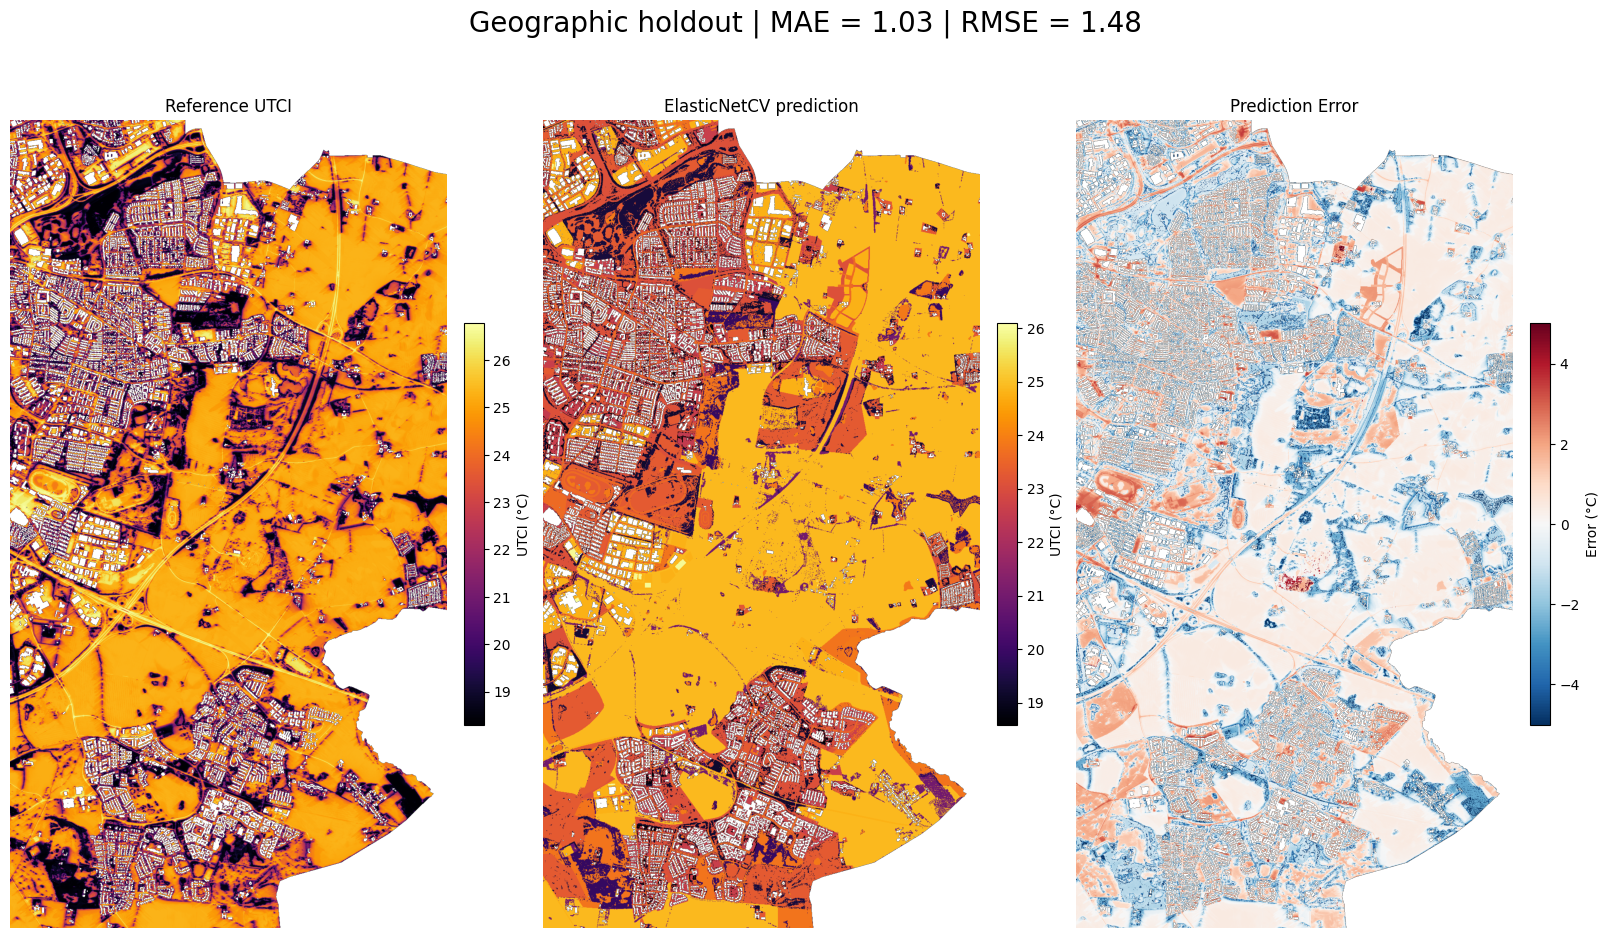

In [51]:
# 1. Initialize full 2D grids filled with NaNs for the whole raster area
obs_grid = np.full((height, width), np.nan)
pred_grid = np.full((height, width), np.nan)
error_grid = np.full((height, width), np.nan)


# 2. Calculate errors for the test set (Actual - Predicted)
y_errors = y_test - y_pred

# 3. Map the test predictions and errors back into their exact 2D pixel locations
# (test_mask is 1D, so we map it back to the 2D grid using the valid 2D test indices)
test_indices_2d = np.where(test_mask.reshape(height, width))
obs_grid[test_indices_2d] = y_test
pred_grid[test_indices_2d] = y_pred
error_grid[test_indices_2d] = y_errors

# 4. Crop to the hold-out region so the plotted data fills the figure
rows, cols = test_indices_2d
row_min, row_max = rows.min(), rows.max() + 1
col_min, col_max = cols.min(), cols.max() + 1
obs_crop = obs_grid[row_min:row_max, col_min:col_max]
pred_crop = pred_grid[row_min:row_max, col_min:col_max]
error_crop = error_grid[row_min:row_max, col_min:col_max]

fig, axes = plt.subplots(1, 3, figsize=(16, 10), constrained_layout=True)

# Plot Observed UTCI on the hold-out area
im1 = axes[0].imshow(obs_crop, cmap='inferno')
axes[0].set_title("Reference UTCI")
fig.colorbar(im1, ax=axes[0], label="UTCI (°C)", fraction=0.046, pad=0.04)

# Plot Predicted UTCI on the hold-out area
im2 = axes[1].imshow(pred_crop, cmap='inferno')
axes[1].set_title("ElasticNetCV prediction")
fig.colorbar(im2, ax=axes[1], label="UTCI (°C)", fraction=0.046, pad=0.04)

# Plot Error (Residuals)
# Diverging colormap ('coolwarm') is great for errors: 
# Red = Overpredicted, Blue = Underpredicted, White = Perfect
im3 = axes[2].imshow(error_crop, cmap='RdBu_r', vmin=-5, vmax=5)
axes[2].set_title("Prediction Error")
fig.colorbar(im3, ax=axes[2], label="Error (°C)", fraction=0.046, pad=0.04)


for ax in axes:
    ax.axis('off')
plt.suptitle(f'Geographic holdout | MAE = {mae:.2f} | RMSE = {rmse:.2f}', fontsize=20)
plt.show()

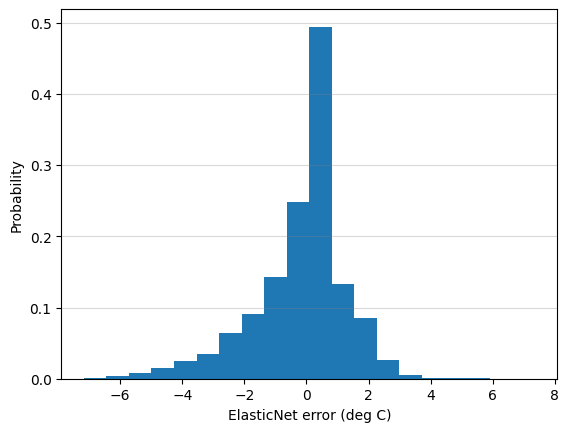

In [40]:
plt.figure()
plt.hist(y_errors, bins=20, density=True)
plt.xlabel('ElasticNet error (deg C)')
plt.ylabel('Probability')
plt.grid(visible=True, which='both', axis='y', alpha=0.3, color='grey')


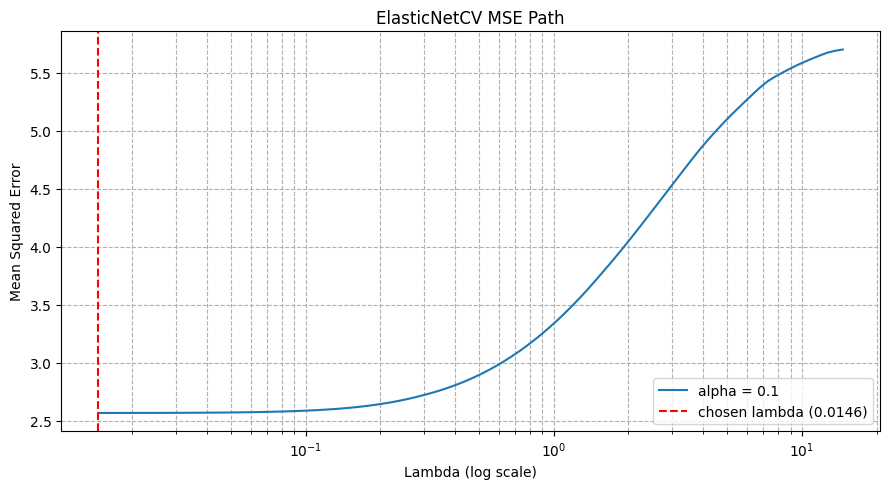

In [43]:
alphas = model.alphas_
mse_path = model.mse_path_

plt.figure(figsize=(9, 5))

# Check if mse_path is 2D (single l1_ratio) or 3D (multiple l1_ratios)
if mse_path.ndim == 2:
    mean_mse = mse_path.mean(axis=-1)
    plt.plot(alphas, mean_mse, label=f"alpha = {model.l1_ratio_}")
else:
    l1_ratios = np.atleast_1d(model.l1_ratio_)
    for i, l1 in enumerate(l1_ratios):
        mean_mse = mse_path[i].mean(axis=-1)
        # Use alphas[i] to match the specific l1_ratio path
        plt.plot(alphas[i], mean_mse, label=f"alpha = {l1}")

# Highlight the chosen optimal alpha
plt.axvline(model.alpha_, color="red", linestyle="--", label=f"chosen lambda ({model.alpha_:.4f})")

plt.xscale("log")
plt.xlabel("Lambda (log scale)")
plt.ylabel("Mean Squared Error")
plt.title("ElasticNetCV MSE Path")
plt.legend()
plt.grid(True, which="both", ls="--")
plt.tight_layout()
plt.show()

/tmp/ipykernel_2488/1449239663.py:17: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()


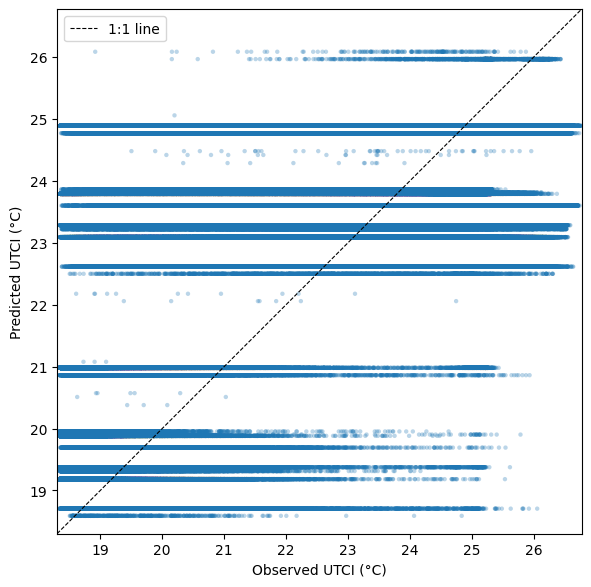

In [48]:
plt.figure(figsize=(6, 6))
# alpha=0.3 helps visualize dense overlapping pixels
plt.scatter(y_test, y_pred, alpha=0.3, s=10, edgecolor="none")

# Determine min and max limits for a square 1:1 plot
min_val = min(np.min(y_test), np.min(y_pred))
max_val = max(np.max(y_test), np.max(y_pred))
plt.plot([min_val, max_val], [min_val, max_val], "k--", linewidth=0.8, label="1:1 line")

plt.xlabel("Observed UTCI (°C)")
plt.ylabel("Predicted UTCI (°C)")
plt.xlim(min_val, max_val)
plt.ylim(min_val, max_val)
plt.gca().set_aspect("equal", adjustable="box")
plt.legend()

plt.tight_layout()
plt.show()

# Climate Scenario Left-Out: Leave-One-Scenario-Out Evaluation

In this part, the model will be trained on different climate scenarios, and tested on unseen climate data in a 10-fold LOO approach. 

The experiment includes 10 present-day and future climate scenarios covering hot and normal summer conditions, the RCP4.5 and RCP8.5 pathways, and projections for 2050 and 2100. The static predictors are the same as in the previous spatial setup. Added to this are now 10 temperature regimes, of which 9 are used for training and 1 used for testing.

In [9]:
import os
import pickle
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio
from sklearn.linear_model import ElasticNetCV
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

In [15]:
feature_paths = [
    "data/processed_5m/input/building_presence_5m.tif",
    "data/processed_5m/input/canopy_presence_5m.tif",
    "data/processed_5m/input/landuse_bostadsbebyggelse_5m.tif",
    "data/processed_5m/input/landuse_h_rdgjord_mark_5m.tif",
    "data/processed_5m/input/landuse_industrimark_5m.tif",
    "data/processed_5m/input/landuse_kyrkog_rd_5m.tif",
    "data/processed_5m/input/landuse_naturomr_de_5m.tif",
    "data/processed_5m/input/landuse_park-_gr_nomr_de_5m.tif",
    "data/processed_5m/input/landuse_ppen_mark_5m.tif",
    "data/processed_5m/input/landuse_s_rskilda_fritidsomr_den_5m.tif",
    "data/processed_5m/input/landuse_tomtmark_5m.tif",
    "data/processed_5m/input/landuse_vatten_5m.tif"
]

utci_paths = [
    "data/processed_5m/target/1994-07-26_UTCI_present_hot_5m_malmo_boundary.tif",
    "data/processed_5m/target/1994-07-26_UTCI_RCP45_2050_5m_malmo_boundary.tif",
    "data/processed_5m/target/1994-07-26_UTCI_RCP45_2100_5m_malmo_boundary.tif",
    "data/processed_5m/target/1994-07-26_UTCI_RCP85_2050_5m_malmo_boundary.tif",
    "data/processed_5m/target/1994-07-26_UTCI_RCP85_2100_5m_malmo_boundary.tif",
    "data/processed_5m/target/2022-06-24_UTCI_current_5m_malmo_boundary.tif",
    "data/processed_5m/target/2022-06-24_UTCI_RCP45_2050_5m_malmo_boundary.tif",
    "data/processed_5m/target/2022-06-24_UTCI_RCP45_2100_5m_malmo_boundary.tif",
    "data/processed_5m/target/2022-06-24_UTCI_RCP85_2050_5m_malmo_boundary.tif",
    "data/processed_5m/target/2022-06-24_UTCI_RCP85_2100_5m_malmo_boundary.tif"
]

climate_paths = [
    "data/processed_5m/future_adjusted/1994-07-26_temperature_C.tif",
    "data/processed_5m/future_adjusted/1994-07-26_temperature_RCP45_2050.tif",
    "data/processed_5m/future_adjusted/1994-07-26_temperature_RCP45_2100.tif",
    "data/processed_5m/future_adjusted/1994-07-26_temperature_RCP85_2050.tif",
    "data/processed_5m/future_adjusted/1994-07-26_temperature_RCP85_2100.tif",
    "data/processed_5m/future_adjusted/2022-06-24_temperature_C.tif",
    "data/processed_5m/future_adjusted/2022-06-24_temperature_RCP45_2050.tif",
    "data/processed_5m/future_adjusted/2022-06-24_temperature_RCP45_2100.tif",
    "data/processed_5m/future_adjusted/2022-06-24_temperature_RCP85_2050.tif",
    "data/processed_5m/future_adjusted/2022-06-24_temperature_RCP85_2100.tif"
]

# Adjust this fraction if needed (0.1 means keep 10% of pixels randomly)
SAMPLE_FRACTION = 0.2
print(f"Loading static features...")
static_features = []
for f_path in feature_paths:
    with rasterio.open(f_path) as src:
        static_features.append(src.read(1).ravel().astype(np.int8))

X_static_all = np.column_stack(static_features)
del static_features
gc.collect()

X_scenarios = []
y_scenarios = []
groups = []

print("Processing climate scenarios with subsampling...")
for fold_idx, (clim_path, utci_path) in enumerate(zip(climate_paths, utci_paths)):
    with rasterio.open(clim_path) as src_c, rasterio.open(utci_path) as src_u:
        clim_img = src_c.read(1)
        utci_img = src_u.read(1)
       
        nodata_c = src_c.nodata if src_c.nodata is not None else -9999
        nodata_u = src_u.nodata if src_u.nodata is not None else -9999
       
        valid = (clim_img != nodata_c) & (utci_img != nodata_u)
        valid_indices = np.where(valid.ravel())[0]
       
        # Subsample indices to save memory
        if SAMPLE_FRACTION < 1.0:
            rng = np.random.default_rng(seed=42)
            valid_indices = rng.choice(
                valid_indices,
                size=int(len(valid_indices) * SAMPLE_FRACTION),
                replace=False
            )
            valid_indices.sort() # Keep spatial order somewhat intact
           
        clim_flat = clim_img.ravel()[valid_indices].reshape(-1, 1).astype(np.float32)
        static_valid = X_static_all[valid_indices].astype(np.float32)
       
        X_combined = np.hstack([clim_flat, static_valid])
       
        X_scenarios.append(X_combined)
        y_scenarios.append(utci_img.ravel()[valid_indices].astype(np.float32))
        groups.append(np.full(len(valid_indices), fold_idx, dtype=np.int8))

del X_static_all
gc.collect()

X = np.vstack(X_scenarios)
y = np.concatenate(y_scenarios)
groups = np.concatenate(groups)

del X_scenarios, y_scenarios
gc.collect()

print(f"Final training matrix shape: {X.shape}")

def train_and_evaluate_loo_cv(X, y, groups, output_dir="outputs/climate_scenario_left_out/checkpoints_fraction02"):
    os.makedirs(output_dir, exist_ok=True)
    unique_groups = np.unique(groups)
    results = {}
   
    for test_group in unique_groups:
        train_idx = groups != test_group
        test_idx = groups == test_group
       
        X_train, y_train = X[train_idx], y[train_idx]
        X_test, y_test = X[test_idx], y[test_idx]
       
        model = ElasticNetCV(
            l1_ratio=1.0,
            cv=3,
            random_state=42,
            n_jobs=1,
            precompute=False,  # <--- Add this line to bypass the float32 Gram matrix validation error
            selection='random'
        )
       
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        mae = mean_absolute_error(y_test, y_pred)
       
        results[test_group] = {
            "mae": mae,
            "model": model,
            "y_test": y_test,
            "y_pred": y_pred,
        }
       
        model_path = os.path.join(output_dir, f"ElasticNetCV_scenario_{test_group}.pkl")
        with open(model_path, "wb") as f:
            pickle.dump(model, f)
           
        print(f"Scenario {test_group} -> MAE: {mae:.4f} | Alpha: {model.alpha_:.4f} | L1: {model.l1_ratio_}")
       
    return results

cv_results = train_and_evaluate_loo_cv(X, y, groups)

Loading static features...
Processing climate scenarios with subsampling...
Final training matrix shape: (11075810, 13)
Scenario 0 -> MAE: 1.0237 | Alpha: 0.0099 | L1: 1.0
Scenario 1 -> MAE: 0.9231 | Alpha: 0.0096 | L1: 1.0
Scenario 2 -> MAE: 0.8501 | Alpha: 0.0092 | L1: 1.0
Scenario 3 -> MAE: 1.0590 | Alpha: 0.0089 | L1: 1.0
Scenario 4 -> MAE: 0.9418 | Alpha: 0.0068 | L1: 1.0
Scenario 5 -> MAE: 1.2031 | Alpha: 0.0065 | L1: 1.0
Scenario 6 -> MAE: 1.0634 | Alpha: 0.0088 | L1: 1.0
Scenario 7 -> MAE: 1.0142 | Alpha: 0.0093 | L1: 1.0
Scenario 8 -> MAE: 1.0868 | Alpha: 0.0095 | L1: 1.0
Scenario 9 -> MAE: 1.1567 | Alpha: 0.0099 | L1: 1.0


Metrics saved to outputs/climate_scenario_left_out/scenario_metrics.csv
               Scenario       MAE  MAE_95CI      RMSE      Bias  Bias_95CI
0        01_present_hot  1.023692  0.001346  1.253021 -0.468352   0.002164
1     02_current_normal  1.203084  0.001814  1.548012  0.001153   0.002883
2     03_rcp85_2050_hot  1.058999  0.001283  1.263477 -0.613579   0.002057
3     04_rcp85_2100_hot  0.941829  0.001617  1.280942  0.676619   0.002026
4     05_rcp45_2050_hot  0.923115  0.001344  1.171747 -0.349286   0.002083
5     06_rcp45_2100_hot  0.850137  0.001390  1.131234 -0.211113   0.002070
6  07_rcp85_2050_normal  1.086842  0.001622  1.392652 -0.135240   0.002581
7  08_rcp85_2100_normal  1.156695  0.002063  1.601520  0.898478   0.002469
8  09_rcp45_2050_normal  1.063388  0.001790  1.433492  0.102364   0.002663
9  10_rcp45_2100_normal  1.014192  0.001874  1.428626  0.244545   0.002621


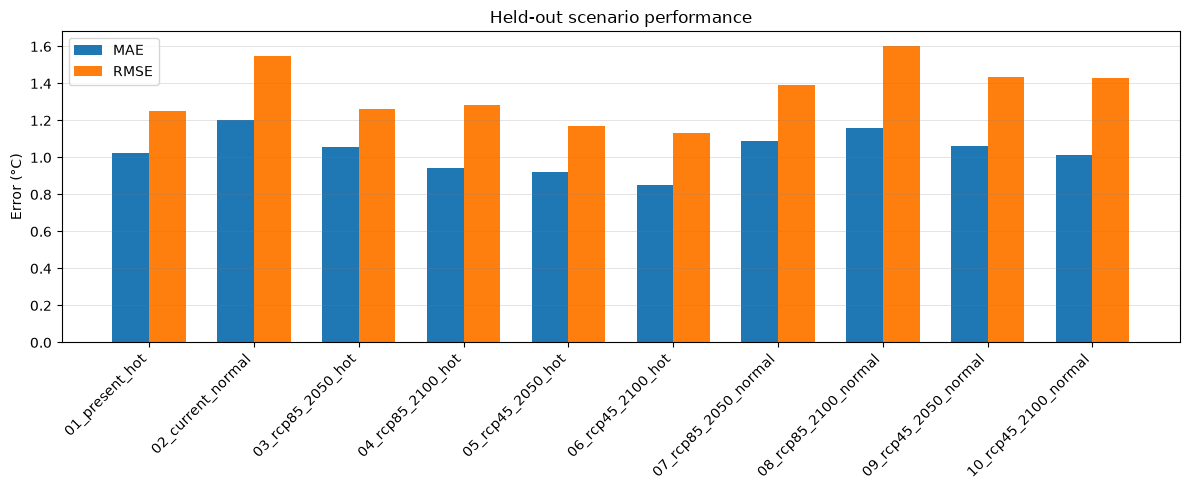

In [16]:
desired_order = [0, 5, 3, 4, 1, 2, 8, 9, 6, 7]
labels = [
    "01_present_hot",
    "02_current_normal",
    "03_rcp85_2050_hot",
    "04_rcp85_2100_hot",
    "05_rcp45_2050_hot",
    "06_rcp45_2100_hot",
    "07_rcp85_2050_normal",
    "08_rcp85_2100_normal",
    "09_rcp45_2050_normal",
    "10_rcp45_2100_normal",
]

table_data = []

for idx, group_id in enumerate(desired_order):
  res = cv_results[group_id]
  y_test = res["y_test"]
  y_pred = res["y_pred"]

  mae = res["mae"]
  rmse = root_mean_squared_error(y_test, y_pred)

  # Residuals (prediction - actual)
  residuals = y_pred - y_test
  bias = np.mean(residuals)

  # 95% Confidence Intervals (margin of error)
  mae_errors = np.abs(residuals)
  mae_ci_95 = 1.96 * (np.std(mae_errors, ddof=1) / np.sqrt(len(mae_errors)))
  bias_ci_95 = 1.96 * (np.std(residuals, ddof=1) / np.sqrt(len(residuals)))

  table_data.append({
      "Scenario": labels[idx],
      "MAE": mae,
      "MAE_95CI": mae_ci_95,
      "RMSE": rmse,
      "Bias": bias,
      "Bias_95CI": bias_ci_95,
  })

df_metrics = pd.DataFrame(table_data)
output_csv = "outputs/climate_scenario_left_out/scenario_metrics.csv"
df_metrics.to_csv(output_csv, index=False)
print(f"Metrics saved to {output_csv}")
print(df_metrics)

# Plotting script
maes = df_metrics["MAE"].values
rmses = df_metrics["RMSE"].values
x = np.arange(len(desired_order))
width = 0.35

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(x - width / 2, maes, width, label="MAE")
ax.bar(x + width / 2, rmses, width, label="RMSE")

ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=45, ha="right")
ax.grid(True, axis='y', which='major', linewidth=0.5, color='grey', alpha=0.3)
ax.set_ylabel("Error (°C)")
ax.set_title("Held-out scenario performance")
ax.legend()

plt.tight_layout()
plt.show()

In [23]:
print(output_csv[0])

o


Scenario 0 -> MAE: 1.0159 | RMSE: 1.2430 | Bias: -0.4669
Scenario 1 -> MAE: 0.9158 | RMSE: 1.1619 | Bias: -0.3492
Scenario 2 -> MAE: 0.8432 | RMSE: 1.1211 | Bias: -0.2114
Scenario 3 -> MAE: 1.0522 | RMSE: 1.2546 | Bias: -0.6140
Scenario 4 -> MAE: 0.9360 | RMSE: 1.2711 | Bias: 0.6741
Scenario 5 -> MAE: 1.1948 | RMSE: 1.5373 | Bias: 0.0029
Scenario 6 -> MAE: 1.0572 | RMSE: 1.4237 | Bias: 0.1029
Scenario 7 -> MAE: 1.0081 | RMSE: 1.4188 | Bias: 0.2447
Scenario 8 -> MAE: 1.0803 | RMSE: 1.3827 | Bias: -0.1351
Scenario 9 -> MAE: 1.1522 | RMSE: 1.5927 | Bias: 0.8973


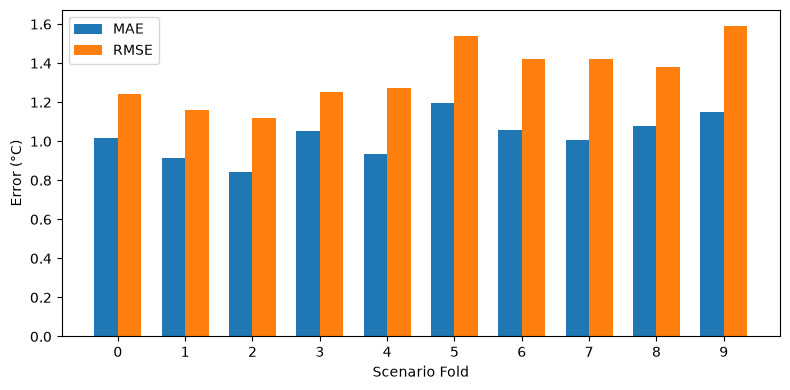

In [9]:
for test_group, res in cv_results.items():
  y_test = res["y_test"]
  y_pred = res["y_pred"]

  res["rmse"] = root_mean_squared_error(y_test, y_pred)
  res["bias"] = np.mean(y_pred - y_test)

  print(
      f"Scenario {test_group} -> MAE: {res['mae']:.4f} | RMSE:"
      f" {res['rmse']:.4f} | Bias: {res['bias']:.4f}"
  )

scenarios = [str(g) for g in cv_results.keys()]
maes = [cv_results[g]["mae"] for g in cv_results.keys()]
rmses = [cv_results[g]["rmse"] for g in cv_results.keys()]

x = np.arange(len(scenarios))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(x - width / 2, maes, width, label="MAE")
ax.bar(x + width / 2, rmses, width, label="RMSE")

ax.set_xticks(x)
ax.set_xticklabels(scenarios)
ax.set_xlabel("Scenario Fold")
ax.set_ylabel("Error (°C)")
ax.legend()

plt.tight_layout()
os.makedirs("outputs/spatial_left_out/plots", exist_ok=True)
plt.savefig(
    "outputs/spatial_left_out/plots/metrics_histogram.png", dpi=300, bbox_inches="tight"
)
plt.show()

In [ ]:
def predict_scenario_raster(model_path, clim_path, feature_paths, output_tif_path):
    """
    Loads a saved model checkpoint and generates a full spatial UTCI prediction raster 
    for a given climate scenario and static features.
    """
    print(f"Loading model from {model_path}...")
    with open(model_path, "rb") as f:
        model = pickle.load(f)
        
    print("Loading static features...")
    static_features = []
    for f_path in feature_paths:
        with rasterio.open(f_path) as src:
            static_features.append(src.read(1).ravel().astype(np.int8))
            
    X_static_all = np.column_stack(static_features)
    del static_features
    
    print(f"Processing climate scenario: {clim_path}")
    with rasterio.open(clim_path) as src_c:
        clim_img = src_c.read(1)
        meta = src_c.meta.copy()
        nodata_c = src_c.nodata if src_c.nodata is not None else -9999
        
        valid = (clim_img != nodata_c)
        valid_flat = valid.ravel()
        
        # Prepare feature matrix for valid pixels
        clim_flat = clim_img[valid].reshape(-1, 1).astype(np.float32)
        static_valid = X_static_all[valid_flat].astype(np.float32)
        X_pred = np.hstack([clim_flat, static_valid])
        
    print("Running spatial predictions...")
    preds = model.predict(X_pred)
    
    # Reconstruct 2D raster
    pred_img = np.full(clim_img.shape, -9999, dtype=np.float32)
    pred_img[valid] = preds
    
    # Update metadata for output raster (float32 format with -9999 nodata)
    meta.update({
        'dtype': 'float32',
        'nodata': -9999,
        'count': 1
    })
    
    os.makedirs(os.path.dirname(output_tif_path), exist_ok=True)
    print(f"Saving prediction raster to {output_tif_path}...")
    with rasterio.open(output_tif_path, 'w', **meta) as dst:
        dst.write(pred_img, 1)
        
    print("Raster export complete!")

In [10]:
# Loop through all 10 climate scenarios and predict using their corresponding left-out model checkpoint
for i, clim_path in enumerate(climate_paths):
    model_checkpoint = f"outputs/climate_scenario_left_out/elasticnet_checkpoints/ElasticNetCV_scenario_{i}.pkl"
    
    # Automatically generate an output filename based on the input climate filename
    clim_filename = os.path.basename(clim_path)
    pred_filename = clim_filename.replace("temperature", "UTCI_predicted").replace(".tif", "_ELNet.tif")
    output_raster = os.path.join("outputs/climate_scenario_left_out/predictions", pred_filename)
    
    print(f"\n--- Processing Scenario {i} ---")
    predict_scenario_raster(model_checkpoint, clim_path, feature_paths, output_raster)


--- Processing Scenario 0 ---
Loading model from outputs/climate_scenario_left_out/elasticnet_checkpoints/ElasticNetCV_scenario_0.pkl...
Loading static features...
Processing climate scenario: data/processed_5m/future_adjusted/1994-07-26_temperature_C.tif
Running spatial predictions...
Saving prediction raster to outputs/climate_scenario_left_out/predictions\1994-07-26_UTCI_predicted_C_ELNet.tif...
Raster export complete!

--- Processing Scenario 1 ---
Loading model from outputs/climate_scenario_left_out/elasticnet_checkpoints/ElasticNetCV_scenario_1.pkl...
Loading static features...
Processing climate scenario: data/processed_5m/future_adjusted/1994-07-26_temperature_RCP45_2050.tif
Running spatial predictions...
Saving prediction raster to outputs/climate_scenario_left_out/predictions\1994-07-26_UTCI_predicted_RCP45_2050_ELNet.tif...
Raster export complete!

--- Processing Scenario 2 ---
Loading model from outputs/climate_scenario_left_out/elasticnet_checkpoints/ElasticNetCV_scenario

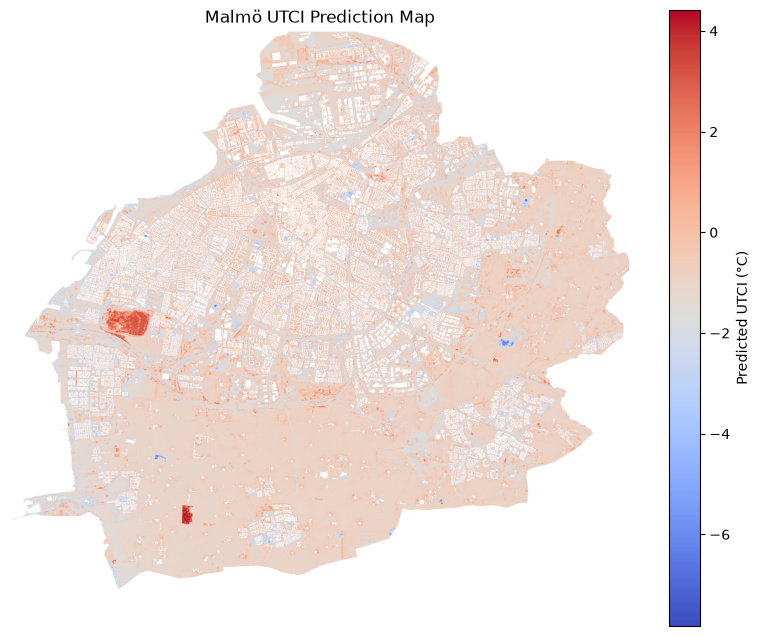

In [13]:
output_tif_path = r"outputs\climate_scenario_left_out\predictions\scenario_holdout\error_maps\01_present_hot_utci_error.tif"

with rasterio.open(output_tif_path) as src:
    pred_img = src.read(1)
    nodata = src.nodata
    
    # Mask out no-data values for clean plotting
    masked_img = np.ma.masked_equal(pred_img, nodata)
    
    plt.figure(figsize=(10, 8))
    # 'coolwarm', 'plasma', or 'inferno' work great for thermal/UTCI maps
    plt.imshow(masked_img, cmap='coolwarm')
    plt.colorbar(label='Predicted UTCI (°C)')
    plt.title("Malmö UTCI Prediction Map")
    plt.axis('off')
    plt.show()

In [ ]:
error_dir = "outputs/climate_scenario_left_out/errors"
os.makedirs(error_dir, exist_ok=True)

for i, (clim_path, utci_path) in enumerate(zip(climate_paths, utci_paths)):
    # Reconstruct prediction file path
    clim_filename = os.path.basename(clim_path)
    pred_filename = clim_filename.replace("temperature", "UTCI_predicted").replace(".tif", "_ELNet.tif")
    pred_path = os.path.join("outputs/climate_scenario_left_out/predictions", pred_filename)
    
    # Define error output file path
    error_filename = clim_filename.replace("temperature", "UTCI_error").replace(".tif", "_ELNet.tif")
    error_path = os.path.join(error_dir, error_filename)
    
    with rasterio.open(pred_path) as src_p, rasterio.open(utci_path) as src_u:
        pred_img = src_p.read(1)
        utci_img = src_u.read(1)
        meta = src_p.meta.copy()
        
        nodata_p = src_p.nodata if src_p.nodata is not None else -9999
        nodata_u = src_u.nodata if src_u.nodata is not None else -9999
        
        # Identify valid overlapping pixels
        valid = (pred_img != nodata_p) & (utci_img != nodata_u)
        
        # Calculate signed error (Prediction - Actual)
        error_img = np.full(pred_img.shape, -9999, dtype=np.float32)
        error_img[valid] = pred_img[valid] - utci_img[valid]
        
        # Calculate quantitative error metrics for valid pixels
        valid_preds = pred_img[valid]
        valid_actuals = utci_img[valid]
        mae = mean_absolute_error(valid_actuals, valid_preds)
        rmse = np.sqrt(mean_squared_error(valid_actuals, valid_preds))
        
        print(f"Scenario {i} -> MAE: {mae:.4f} °C | RMSE: {rmse:.4f} °C")
        
        # Save error raster
        meta.update({'dtype': 'float32', 'nodata': -9999, 'count': 1})
        with rasterio.open(error_path, 'w', **meta) as dst:
            dst.write(error_img, 1)

print(f"\nAll error rasters successfully saved to {error_dir}/")

Scenario 0 -> MAE: 1.0180 °C | RMSE: 1.2478 °C
Scenario 1 -> MAE: 0.9183 °C | RMSE: 1.1673 °C
Scenario 2 -> MAE: 0.8462 °C | RMSE: 1.1276 °C
Scenario 3 -> MAE: 1.0536 °C | RMSE: 1.2582 °C
Scenario 4 -> MAE: 0.9423 °C | RMSE: 1.2813 °C
Scenario 5 -> MAE: 1.1997 °C | RMSE: 1.5468 °C
Scenario 6 -> MAE: 1.0620 °C | RMSE: 1.4333 °C
Scenario 7 -> MAE: 1.0135 °C | RMSE: 1.4293 °C
Scenario 8 -> MAE: 1.0844 °C | RMSE: 1.3907 °C
Scenario 9 -> MAE: 1.1606 °C | RMSE: 1.6048 °C

All error rasters successfully saved to outputs/climate_scenario_left_out/errors/


In [ ]:
from mpl_toolkits.axes_grid1 import make_axes_locatable
from matplotlib.colors import Normalize

# ==========================================
# 1. SPECIFY YOUR OUTPUT FOLDER HERE
# ==========================================
figures_output_dir = "outputs/climate_scenario_left_out/figures"
# ==========================================

os.makedirs(figures_output_dir, exist_ok=True)

def get_scenario_name(fold_idx):
    """Helper to get a clean descriptive name based on index."""
    names = [
        "1994 Present Hot",
        "1994 RCP4.5 2050",
        "1994 RCP4.5 2100",
        "1994 RCP8.5 2050",
        "1994 RCP8.5 2100",
        "2022 Current",
        "2022 RCP4.5 2050",
        "2022 RCP4.5 2100",
        "2022 RCP8.5 2050",
        "2022 RCP8.5 2100"
    ]
    return f"{fold_idx:02d} {names[fold_idx]}"

def plot_4panel_performance(fold_idx, pred_path, utci_path, output_dir, cv_results_data):
    """Recreates the 4-panel spatial performance figure with dark theme."""
    scenario_name = get_scenario_name(fold_idx)
    
    # Define color maps and standard ranges
    cmap_utci = plt.cm.turbo
    cmap_error = plt.cm.coolwarm
    cmap_abs_error = plt.cm.inferno

    # UTCI standard range (modify if needed)
    utci_norm = Normalize(vmin=21, vmax=37)
    
    # Signed Error standard range (modify if needed)
    error_norm = Normalize(vmin=-3, vmax=3)
    
    # Absolute Error standard range (modify if needed)
    abs_error_norm = Normalize(vmin=0, vmax=3)

    print(f"Generating 4-panel figure for: {scenario_name}...")

    with rasterio.open(pred_path) as src_p, rasterio.open(utci_path) as src_u:
        pred_img = src_p.read(1)
        utci_img = src_u.read(1)
        
        nodata_p = src_p.nodata if src_p.nodata is not None else -9999
        nodata_u = src_u.nodata if src_u.nodata is not None else -9999
        
        valid_mask = (pred_img != nodata_p) & (utci_img != nodata_u)
        
        # Calculate errors
        diff = pred_img - utci_img
        abs_diff = np.abs(diff)
        
        # Pull overall metrics from training results
        mae = cv_results_data["mae"]
        num_pixels = valid_mask.sum()
        
        # Apply masks for plotting
        pred_plot = np.ma.masked_where(~valid_mask, pred_img)
        utci_plot = np.ma.masked_where(~valid_mask, utci_img)
        diff_plot = np.ma.masked_where(~valid_mask, diff)
        abs_diff_plot = np.ma.masked_where(~valid_mask, abs_diff)

        # Set up figure with dark theme
        plt.style.use('dark_background')
        fig, axes = plt.subplots(1, 4, figsize=(24, 6), sharey=True, sharex=True)
        
        # Remove background gray of the entire plot area to match image
        fig.patch.set_facecolor('#1a1a1a') # Or just black

        # Subplot Titles and color bar labels
        titles = ["Actual UTCI (°C)", "Predicted UTCI (°C)", "Error: predicted - actual", "Absolute error"]
        cbar_labels = ["UTCI (°C)", "UTCI (°C)", "Error (°C)", "Absolute error (°C)"]

        images = [utci_plot, pred_plot, diff_plot, abs_diff_plot]
        cmaps = [cmap_utci, cmap_utci, cmap_error, cmap_abs_error]
        norms = [utci_norm, utci_norm, error_norm, abs_error_norm]

        for i, ax in enumerate(axes):
            im = ax.imshow(images[i], cmap=cmaps[i], norm=norms[i])
            ax.set_title(titles[i], color='white', fontsize=12)
            ax.axis('off')
            
            # Create colorbar
            divider = make_axes_locatable(ax)
            cax = divider.append_axes("right", size="5%", pad=0.1)
            cbar = fig.colorbar(im, cax=cax)
            cbar.set_label(cbar_labels[i], color='white')
            cbar.ax.tick_params(color='white', labelcolor='white')

        # Main Title (includes the model name)
        plt.suptitle(f"{scenario_name} - ElasticNetCV Held-out prediction", 
                     color='white', fontsize=16, y=0.98)

        # Footer Metrics Text (similar to original)
        metrics_text = f"MAE: {mae:.2f} °C | Evaluated pixels: {num_pixels:,}"
        fig.text(0.5, 0.05, metrics_text, ha='center', color='white', fontsize=11)

        # Save the figure
        filename = f"{scenario_name.replace(' ', '_')}_Performance_ELNet.png"
        output_path = os.path.join(output_dir, filename)
        plt.savefig(output_path, dpi=150, bbox_inches='tight', facecolor='#1a1a1a')
        
        # Close plot to free memory
        plt.close(fig)

# ==========================================
# 2. RUN LOOP FOR ALL SCENARIOS
# ==========================================
# (Assumes climate_paths, utci_paths, and cv_results exist from previous steps)

# Note: We need cv_results specifically to pull the MAE metric for the footer.
if 'cv_results' not in locals():
    print("Error: 'cv_results' dictionary not found. Please run the training step first.")
else:
    for i, clim_path in enumerate(climate_paths):
        # 1. Pull the actual UTCI path
        utci_path = utci_paths[i]
        
        # 2. Reconstruct the prediction raster path
        clim_filename = os.path.basename(clim_path)
        pred_filename = clim_filename.replace("temperature", "UTCI_predicted").replace(".tif", "_ELNet.tif")
        pred_path = os.path.join("outputs/climate_scenario_left_out/predictions", pred_filename)
        
        # 3. Pull metrics for this specific test fold
        data_metrics = cv_results[i]
        
        # 4. Generate the plot
        plot_4panel_performance(i, pred_path, utci_path, figures_output_dir, data_metrics)

    print(f"\nAll performance figures saved to {figures_output_dir}/")

Generating 4-panel figure for: 00 1994 Present Hot...
Generating 4-panel figure for: 01 1994 RCP4.5 2050...
Generating 4-panel figure for: 02 1994 RCP4.5 2100...
Generating 4-panel figure for: 03 1994 RCP8.5 2050...
Generating 4-panel figure for: 04 1994 RCP8.5 2100...
Generating 4-panel figure for: 05 2022 Current...
Generating 4-panel figure for: 06 2022 RCP4.5 2050...
Generating 4-panel figure for: 07 2022 RCP4.5 2100...
Generating 4-panel figure for: 08 2022 RCP8.5 2050...
Generating 4-panel figure for: 09 2022 RCP8.5 2100...

All performance figures saved to outputs/climate_scenario_left_out/figures/
